<a href="https://colab.research.google.com/github/vishwakumar1311/MiniGPT/blob/main/GPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# imports and device; load input.txt from this repo (downloaded from GitHub if not found locally)
import os
import urllib.request

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn import functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

DATA_URL = "https://raw.githubusercontent.com/vishwakumar1311/MiniGPT/main/input.txt"
if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(DATA_URL, "input.txt")

text = open("input.txt", encoding="utf-8").read()
print(f"{len(text):,} characters")

Using device: cpu


1,115,394 characters


In [2]:
# character-level vocabulary and 90/10 train/validation split
chars = sorted(set(text))
vocab_size = len(chars)
print("".join(chars))
print(vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: "".join(itos[i] for i in l)
assert decode(encode("Hello Eve")) == "Hello Eve"

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print(train_data.shape, val_data.shape)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65
torch.Size([1003854]) torch.Size([111540])


In [3]:
# hyperparameters
n_embd = 90
num_heads = 6
num_blocks = 4
block_size = 128      # context length
batch_size = 16
dropout = 0.1
learning_rate = 1e-3
max_steps = 11000
eval_interval = 1000
eval_iters = 200

torch.manual_seed(1337)

def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model):
    out = {}
    model.eval()
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

In [4]:
# transformer building blocks: attention, feed-forward, layer norm, embeddings
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
        self.head_size = head_size

    def forward(self, x):
        B, T, C = x.shape
        k, q, v = self.key(x), self.query(x), self.value(x)
        wei = q @ k.transpose(-2, -1) * self.head_size ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class LayerNorm(nn.Module):
    def __init__(self, n_embd, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(n_embd))
        self.beta = nn.Parameter(torch.zeros(n_embd))

    def forward(self, x):
        mean = x.mean(-1, keepdim=True)
        var = x.var(-1, keepdim=True, unbiased=False)
        return self.gamma * (x - mean) / torch.sqrt(var + self.eps) + self.beta

class Embeddings(nn.Module):
    def __init__(self, n_embd, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, idx):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        return self.dropout(self.token_embedding_table(idx) + self.position_embedding_table(pos))

class Block(nn.Module):
    def __init__(self, n_embd, num_heads):
        super().__init__()
        self.sa = MultiHeadAttention(num_heads, n_embd // num_heads)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = LayerNorm(n_embd)
        self.ln2 = LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

In [5]:
# GPT model
class GPT(nn.Module):
    def __init__(self, n_embd, vocab_size, num_heads, num_blocks):
        super().__init__()
        self.embedding = Embeddings(n_embd, vocab_size)
        self.blocks = nn.Sequential(*[Block(n_embd, num_heads) for _ in range(num_blocks)])
        self.ln = LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        x = self.embedding(idx)
        x = self.blocks(x)
        x = self.ln(x)
        logits = self.lm_head(x)  # (B, T, vocab_size)
        if targets is None:
            return logits, None
        B, T, C = logits.shape
        loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            probs = F.softmax(logits[:, -1, :], dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

model = GPT(n_embd, vocab_size, num_heads, num_blocks).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

415,865 parameters


In [6]:
# train with AdamW and save the weights
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
history = []

for step in range(max_steps + 1):
    if step % eval_interval == 0:
        losses = estimate_loss(model)
        history.append((step, losses["train"], losses["val"]))
        print(f"step {step:5d}  train loss {losses['train']:.4f}  val loss {losses['val']:.4f}")
    if step == max_steps:
        break
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

torch.save(model.state_dict(), "minigpt.pt")

step     0  train loss 4.1921  val loss 4.1949


step  1000  train loss 2.0969  val loss 2.1476


step  2000  train loss 1.7249  val loss 1.8639


step  3000  train loss 1.5908  val loss 1.7546


step  4000  train loss 1.5170  val loss 1.6941


...

step  7000  train loss 1.4076  val loss 1.6003


step  8000  train loss 1.3934  val loss 1.5933


step  9000  train loss 1.3798  val loss 1.5804


step 10000  train loss 1.3642  val loss 1.5670


step 11000  train loss 1.3563  val loss 1.5567


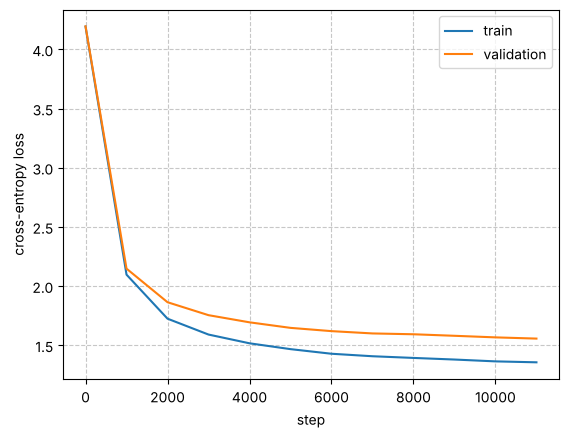

In [7]:
# plot train and validation loss
steps, tr, va = zip(*history)
plt.plot(steps, tr, label="train")
plt.plot(steps, va, label="validation")
plt.xlabel("step")
plt.ylabel("cross-entropy loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

In [8]:
# generate 500 characters starting from a newline
model.eval()
torch.manual_seed(1337)
context = torch.zeros((1, 1), dtype=torch.long, device=device)  # token 0 is the newline character
generated = model.generate(context, max_new_tokens=500)
print(decode(generated[0].tolist()))


CORIOLANUS:
The Either, long heaven,
That an one a power of this termand of now.

KING EDWARD IV:
But you did have come too provost?

KING HENRY VI:
Ah, whom fit is father, to take; and the grave's being right
This mercy, my heart, till I she not black patient?

CORIOLANUS:
I fearly a aught will tempt put of wears,
I am this son that Lancaster: how issue he hath espection
The beging a ship? God's words, ghost: baliones, coast it cloom,
And that I will be you wedden,
To him the surp'd achurate hi
